# Embedding-space geometry

Three questions about the conditioning space one emulate run learned, answered from that
run's own artifacts:

1. **Shape** — PCA / t-SNE / UMAP projections, coloured by device label. Clusters, outliers,
   empty regions. *Distances on the nonlinear plots are not metric* — read them for shape and
   grouping only, never for "how far apart".
2. **Emptiness** — for any point (a device, an enrolled row, the halfway point between two
   amps) the distance to its nearest **trained** embedding, and whether measured ESR tracks
   that distance. This is the part that turns "blends phase-cancel" into a checkable rule.
3. **Shell test** — the distribution of ‖e‖. Tight spread ⇒ the table lives on a shell, which
   is exactly when straight-line blending shrinks the vector and slerp is the right fix. Wide
   spread ⇒ that assumption does not hold and slerp buys little.

**Trained** rows (the run's table) and **enrolled** rows (fitted later against the frozen
network — corpus holdout devices and one-off capture pairs) are kept as separate groups
throughout. Only the trained table defines "known territory": every nearest-neighbour
distance is measured against it, and enrolled points are only ever queried into it.

Conventions match `emulate_demo` / `embedding_playground`: **open-amp3000** kernel, run from
the repo root, checkpoint temp-copied so this is safe while a run is still writing.

In [1]:
import json
import os
import shutil
import tempfile
from pathlib import Path

# run from the repo root so the config's relative data paths resolve
if not Path('configs').is_dir() and (Path.cwd().parent / 'configs').is_dir():
    os.chdir(Path.cwd().parent)
print('cwd:', Path.cwd())

import numpy as np
import pandas as pd
import torch

RESULTS = Path('results/emulate')


def enroll_artifacts(run: Path):
    """Every enrolled-embedding file under a run: ('holdout'|'pair', path)."""
    found = []
    table = run / 'enroll' / 'enrolled_embeddings.pt'      # corpus holdout devices, one table
    if table.is_file():
        found.append(('holdout', table))
    found += [('pair', p) for p in                          # one wet/dry capture each
              sorted((run / 'enroll' / 'pairs').glob('*/enrolled_pair.pt'))]
    return found


rows = []
for emb_path in sorted(RESULTS.glob('**/embedding.pt')):
    run = emb_path.parent
    mpath = run / 'metrics.json'
    meta = json.loads(mpath.read_text(encoding='utf-8')) if mpath.is_file() else {}
    enr = enroll_artifacts(run)
    rows.append({'run': str(run.relative_to(RESULTS)),
                 'arch': meta.get('arch', '?'),
                 'n_devices': meta.get('n_devices', -1),
                 'dim': meta.get('embedding_dim', -1),
                 'best_val_esr': meta.get('best_val_esr', np.nan),
                 'enroll_files': len(enr),
                 'per_device_esr': (run / 'per_device_esr.csv').is_file()})

RUNS = pd.DataFrame(rows).sort_values('run').reset_index(drop=True)
print(f'{len(RUNS)} run(s) with a trained embedding table:')
RUNS

cwd: /m/home/home3/37/thieun1/unix/Project/AllAmpsOnMe


22 run(s) with a trained embedding table:


,run,arch,n_devices,dim,best_val_esr,enroll_files,per_device_esr
0,delta_a2_256,delta_wavenet,405,256,0.063910,0,False
1,delta_a2_r16_256,delta_wavenet,405,256,0.046917,0,False
2,delta_a2_r32_512,delta_wavenet,405,512,0.037358,0,True
3,delta_a2_tanh_r32_512,delta_wavenet,405,512,0.033386,3,True
4,legacy/channels32,?,405,64,0.125082,0,False
5,legacy/delta_a2_256_attempt1_unscaled,delta_wavenet,405,256,0.317869,0,False
6,legacy/embed256,?,405,256,0.135960,2,False
7,legacy/paper,?,405,64,0.173885,0,False
8,mlpfilm_a2_256,mlpfilm_wavenet,405,256,0.087203,0,False
9,mlpfilm_a2_h16_256,mlpfilm_wavenet,405,256,0.104473,0,False


Pick the run below. Everything downstream reads from it — embedding tables from different
runs are **not** comparable (separate random inits, separate spaces), so one run at a time.

In [2]:
RUN_DIR = RESULTS / 'nam_a2_256_mixed_n10'    # <- change me
# 'nam_a2_tanh_ch16_512' and 'delta_a2_tanh_r32_512' carry a full ~45-device enrolled
# holdout table; most runs only have one-off capture pairs.

from openamp.core.config import load_config
from openamp.emulate.dataset import manifest_signature
from openamp.emulate.evaluate import load_model

with tempfile.TemporaryDirectory() as td:      # temp copy: safe while the run is writing
    shutil.copy(RUN_DIR / 'checkpoint.pt', Path(td) / 'checkpoint.pt')
    model, CK = load_model(Path(td), 'cpu')
model.eval()

R = int(CK['receptive_field'])
ARCH = CK['emulate_cfg'].get('arch', 'film_tcn')
ID2ROW = {int(d): int(r) for d, r in CK['id_to_idx'].items()}
ROW2ID = {r: d for d, r in ID2ROW.items()}
X_TRAINED = model.embedding.weight.detach().cpu().numpy().copy()   # [N_trained, E]
DIM = X_TRAINED.shape[1]
TRAINED_IDS = [ROW2ID[i] for i in range(len(X_TRAINED))]

if ARCH == 'tabledelta_wavenet':
    print('! tabledelta_wavenet has no shared conditioning space: its "embedding" is a raw '
          'per-device weight residual. Geometry below is not comparable to the FiLM runs.')

# data root = the one whose manifest hashes to the run's manifest_sha256 (data/ vs
# data_mixed/ vs data_sweep/ hold different corpora and different renders)
DATA_DIR, sig = None, CK.get('manifest_sha256', '')
for d in sorted(Path('.').glob('data*')):
    if not (d / 'manifests').is_dir():
        continue
    try:
        if manifest_signature(load_config(data_dir=d)) == sig:
            DATA_DIR = d
            break
    except Exception:
        continue
cfg = load_config(data_dir=DATA_DIR) if DATA_DIR is not None else load_config()

print(f"run {CK['name']}  arch={ARCH}  table={X_TRAINED.shape[0]} x {DIM}  "
      f"epoch={CK['epoch']}  val_esr={CK['val_esr']:.4f}")
print(f"holdout ids in checkpoint: {len(CK.get('holdout_ids', []))}")
print('data root:', DATA_DIR if DATA_DIR is not None
      else f'(no data*/ matches manifest_sha256 {sig[:12]} -- falling back to the config default '
           f'{load_config().data_dir}; renders/ESR cells may be wrong)')

run nam_a2_256_mixed_n10  arch=film_wavenet  table=404 x 256  epoch=91  val_esr=0.0865
holdout ids in checkpoint: 46
data root: data_mixed


In [3]:
# --- labels + the ESR each row already has on disk ------------------------------------
LABEL_COLS = ['make', 'model', 'gain_bucket', 'architecture']
cat = (pd.read_parquet(cfg.manifest_path).drop_duplicates('device_id')
       .set_index('device_id'))


def label_frame(device_ids):
    """Catalog labels for device ids, 'unknown' where the manifest has no row."""
    idx = pd.Index([int(d) for d in device_ids], name='device_id')
    out = cat.reindex(idx)[LABEL_COLS].astype(object)
    return out.where(out.notna(), 'unknown').reset_index()


esr_trained = {}
pde = RUN_DIR / 'per_device_esr.csv'
if pde.is_file():
    t = pd.read_csv(pde)
    esr_trained = dict(zip(t['device_id'].astype(int), t['test_ESR'].astype(float)))
else:
    print('(no per_device_esr.csv for this run -- the ESR-vs-distance panel will be '
          'enrolled-rows-only; `openamp emulate-eval` writes it)')

TRAINED = label_frame(TRAINED_IDS)
TRAINED['source'] = 'trained'
TRAINED['name'] = TRAINED['device_id'].astype(str)
TRAINED['esr'] = [esr_trained.get(int(d), np.nan) for d in TRAINED_IDS]
TRAINED['esr_kind'] = 'test (per_device_esr.csv)'

# --- enrolled rows: kept apart from the table, never mixed into it ---------------------
vecs, meta = [], []
for kind, path in enroll_artifacts(RUN_DIR):
    art = torch.load(path, map_location='cpu', weights_only=False)
    v = art['embedding'].detach().cpu().numpy()
    if v.shape[1] != DIM:
        print(f'! skipping {path.parent.name}: dim {v.shape[1]} != table dim {DIM}')
        continue
    base = art.get('base_run')
    if base and base != CK['name']:
        print(f'! {path.parent.name} was fitted against run {base!r}, not {CK["name"]!r} -- skipping')
        continue
    if kind == 'holdout':
        per = {int(k): dict(val) for k, val in art.get('per_device', {}).items()}
        for j, d in enumerate(int(x) for x in art['device_ids']):
            vecs.append(v[j])
            meta.append({'device_id': d, 'source': 'enrolled-holdout',
                         'name': str(d), 'esr': per.get(d, {}).get('test_esr', np.nan),
                         'esr_kind': 'test (enrollment)'})
    else:
        vecs.append(v[0])
        meta.append({'device_id': -1, 'source': 'enrolled-pair',
                     'name': art.get('name', path.parent.name),
                     'esr': art.get('val_esr_render_raw', np.nan),
                     'esr_kind': 'val render (pair)'})

X_ENROLLED = np.asarray(vecs, dtype=np.float32).reshape(-1, DIM)
if len(meta):
    ENROLLED = pd.DataFrame(meta)
    lab = label_frame(ENROLLED['device_id']).drop(columns='device_id')
    ENROLLED = pd.concat([ENROLLED.reset_index(drop=True), lab], axis=1)
else:
    ENROLLED = pd.DataFrame(columns=list(TRAINED.columns))
    print('(this run has no enrolled embeddings -- enrolled series will be empty)')

print(f'trained rows : {len(X_TRAINED):4d}')
for s, n in ENROLLED['source'].value_counts().items():
    print(f'{s:13s}: {n:4d}')
ENROLLED[['name', 'source', 'make', 'gain_bucket', 'esr', 'esr_kind']].head(10)

trained rows :  404
enrolled-pair:    1


,name,source,make,gain_bucket,esr,esr_kind
0,nam_7. EVH Stealth G6 B7 M5 T7 P7 D5,enrolled-pair,unknown,unknown,0.142764,val render (pair)


## 1 · Shape of the space

PCA is linear (its axes are real directions in the embedding space); t-SNE and UMAP are
nonlinear and better at exposing clusters and gaps, at the cost of metric meaning.

How the enrolled rows are placed differs by method, and it matters:

- **PCA** and **UMAP** are fit on the **trained table only**, then the enrolled rows are
  *transformed into* that fitted space — an honest "where does this new device land in the
  space the run learned".
- **t-SNE** has no out-of-sample transform, so it is fit on the union. The enrolled rows
  therefore influence the trained layout slightly. Marked, not hidden.

`COLOR_BY` picks the label. Note the corpus has no amp-vs-pedal split to colour by — every
capture in the manifest is `gear_type == 'amp'` — so the available label axes are
`gain_bucket` (clean / crunch / high_gain), `architecture` (A1 / A2), and the free-text
`make` / `model`, which are folded to the top 4 plus *other* rather than cycling hues.

In [4]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

SEED = 0
TSNE_PERPLEXITY = 30        # < n_trained; 5-50 is the usual range
UMAP_NEIGHBORS = 15         # small = local structure, large = global
UMAP_MIN_DIST = 0.10

n_tr, n_en = len(X_TRAINED), len(X_ENROLLED)
EMPTY = np.zeros((0, 2))

pca = PCA(n_components=min(50, n_tr, DIM), random_state=SEED).fit(X_TRAINED)
EVR = pca.explained_variance_ratio_
P_PCA = (pca.transform(X_TRAINED)[:, :2],
         pca.transform(X_ENROLLED)[:, :2] if n_en else EMPTY)

ts = TSNE(n_components=2, perplexity=min(TSNE_PERPLEXITY, (n_tr + n_en - 1) / 3),
          init='pca', learning_rate='auto', random_state=SEED).fit_transform(
              np.vstack([X_TRAINED, X_ENROLLED]) if n_en else X_TRAINED)
P_TSNE = (ts[:n_tr], ts[n_tr:] if n_en else EMPTY)

um = umap.UMAP(n_components=2, n_neighbors=min(UMAP_NEIGHBORS, n_tr - 1),
               min_dist=UMAP_MIN_DIST, metric='euclidean',
               random_state=SEED).fit(X_TRAINED)
try:
    P_UMAP = (um.embedding_, um.transform(X_ENROLLED) if n_en else EMPTY)
except Exception as e:                      # transform needs >1 query point in some builds
    print(f'(umap.transform failed: {e!r} -- enrolled rows omitted from the UMAP panel)')
    P_UMAP = (um.embedding_, EMPTY)

print(f'PCA: top-2 explain {100 * EVR[:2].sum():.1f}% of table variance, '
      f'top-10 {100 * EVR[:10].sum():.1f}%  (participation ratio '
      f'{EVR.sum() ** 2 / (EVR ** 2).sum():.2f} of {min(n_tr, DIM)})')

/u/37/thieun1/unix/anaconda3/envs/open-amp3000/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


PCA: top-2 explain 9.5% of table variance, top-10 26.9%  (participation ratio 33.14 of 256)


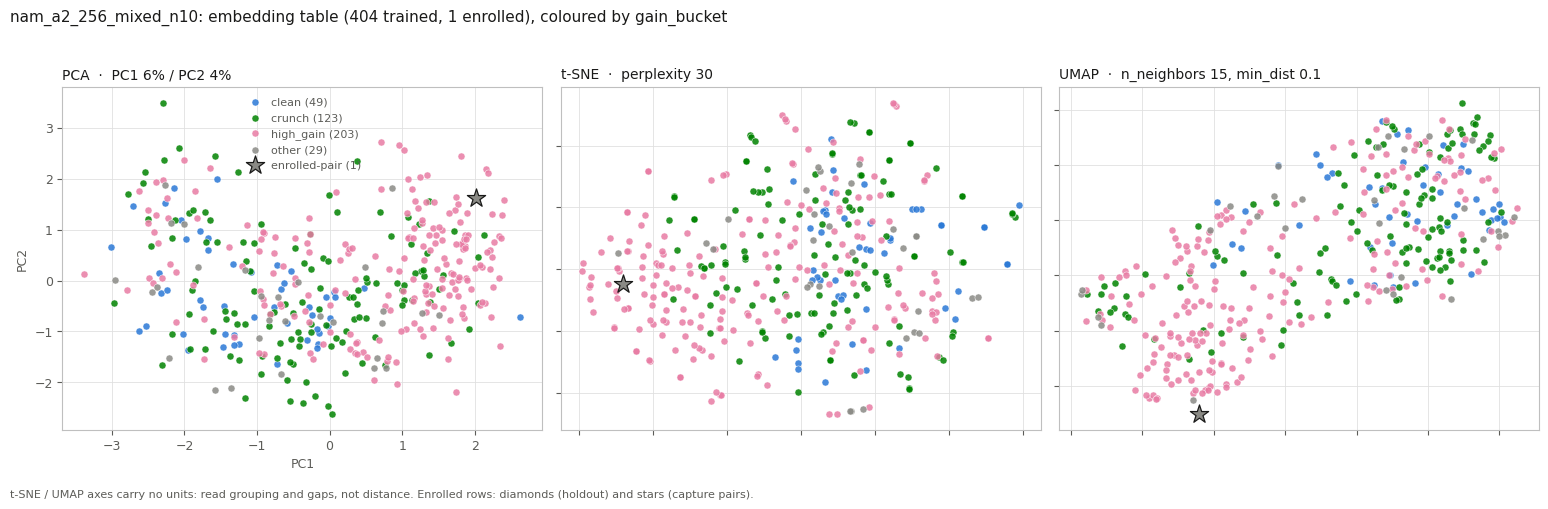

In [5]:
import matplotlib.pyplot as plt

# validated categorical palette, fixed slot order (see notebooks/embedding_playground);
# 4 slots clear the all-pairs CVD check, so a 5th group folds into OTHER rather than cycling
CAT = ['#2a78d6', '#008300', '#e87ba4', '#eda100']
OTHER, INK, INK2 = '#8a8a85', '#1a1a19', '#5c5c58'
GRID = dict(color='0.88', linewidth=0.6)
plt.rcParams.update({'axes.edgecolor': '0.75', 'axes.labelcolor': INK2,
                     'xtick.color': INK2, 'ytick.color': INK2, 'font.size': 9})

COLOR_BY = 'gain_bucket'    # 'gain_bucket' | 'architecture' | 'make' | 'model'

FIXED_ORDER = {'gain_bucket': ['clean', 'crunch', 'high_gain'],
               'architecture': ['A1', 'A2']}


def color_groups(column):
    """(ordered group names, {name: colour}) -- colour follows the entity, never rank."""
    vals = TRAINED[column].astype(str)
    order = [g for g in FIXED_ORDER.get(column, []) if g in set(vals)]
    if not order:                                     # free-text column: top 4 by count
        order = [g for g in vals.value_counts().index if g != 'unknown'][:len(CAT)]
    order = order[:len(CAT)]
    colors = {g: CAT[i] for i, g in enumerate(order)}
    return order, colors


def group_of(frame, column, order):
    g = frame[column].astype(str)
    return g.where(g.isin(order), 'other')


ORDER, COLORS = color_groups(COLOR_BY)
COLORS['other'] = OTHER


def projection_panel(ax, proj, title):
    tr, en = proj
    g = group_of(TRAINED, COLOR_BY, ORDER)
    for name in ORDER + ['other']:
        m = (g == name).to_numpy()
        if m.any():
            ax.scatter(tr[m, 0], tr[m, 1], s=26, c=COLORS[name], linewidths=0.4,
                       edgecolors='white', alpha=0.85, label=f'{name} ({m.sum()})',
                       zorder=2)
    if len(en):
        ge = group_of(ENROLLED, COLOR_BY, ORDER).to_numpy()
        for src, marker, size in (('enrolled-holdout', 'D', 46), ('enrolled-pair', '*', 190)):
            m = (ENROLLED['source'] == src).to_numpy()[:len(en)]
            if m.any():
                ax.scatter(en[m, 0], en[m, 1], s=size, marker=marker,
                           c=[COLORS.get(x, OTHER) for x in ge[m]], linewidths=0.9,
                           edgecolors=INK, label=f'{src} ({m.sum()})', zorder=3)
    ax.set_title(title, color=INK, fontsize=10, loc='left')
    ax.grid(True, **GRID)
    ax.set_axisbelow(True)


fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.0))
projection_panel(axes[0], P_PCA,
                 f'PCA  ·  PC1 {100 * EVR[0]:.0f}% / PC2 {100 * EVR[1]:.0f}%')
projection_panel(axes[1], P_TSNE, f't-SNE  ·  perplexity {TSNE_PERPLEXITY}')
projection_panel(axes[2], P_UMAP,
                 f'UMAP  ·  n_neighbors {UMAP_NEIGHBORS}, min_dist {UMAP_MIN_DIST}')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
for ax in axes[1:]:
    ax.set_xticklabels([])
    ax.set_yticklabels([])
axes[0].legend(loc='best', frameon=False, fontsize=8, labelcolor=INK2, handletextpad=0.4)
fig.suptitle(f'{CK["name"]}: embedding table ({n_tr} trained, {n_en} enrolled), '
             f'coloured by {COLOR_BY}', color=INK, fontsize=11, x=0.005, ha='left')
fig.text(0.005, 0.005, 't-SNE / UMAP axes carry no units: read grouping and gaps, '
         'not distance. Enrolled rows: diamonds (holdout) and stars (capture pairs).',
         color=INK2, fontsize=8)
fig.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

## 2 · Emptiness — distance to the nearest trained embedding

`nn_distance(P)` is the whole tool: for any point it returns the distance to the closest row
of the **trained** table. Large ⇒ unmapped territory. Trained rows are measured
leave-one-out (their own row excluded), so all the numbers below are "distance to a *different*
known device" and are directly comparable.

Four populations, for scale:

- **trained (LOO)** — how dense the learned table is around a known device.
- **enrolled** — where fitted-later devices land relative to that density.
- **pair midpoints** — `0.5·(a + b)` for random trained pairs: the blend case.
- **random in-distribution** — samples drawn from the table's own PCA covariance. A point
  that is "statistically typical" but not any real device.

In [6]:
from sklearn.neighbors import NearestNeighbors

METRIC = 'euclidean'        # 'cosine' swaps this to a direction-only reading
NN = NearestNeighbors(metric=METRIC).fit(X_TRAINED)


def nn_distance(P, k=1, self_rows=None):
    """Distance from each row of P to its k-th nearest *trained* embedding.

    self_rows: table row index to exclude per query (leave-one-out for trained rows).
    """
    q = np.atleast_2d(np.asarray(P, dtype=np.float64))
    n_ask = min(len(X_TRAINED), k + (2 if self_rows is not None else 0))
    d, i = NN.kneighbors(q, n_neighbors=n_ask)
    if self_rows is None:
        return d[:, k - 1]
    self_rows = np.asarray(self_rows)
    return np.array([dd[ii != s][k - 1] for dd, ii, s in zip(d, i, self_rows)])


rng = np.random.default_rng(SEED)
N_PROBE = 400

ia, ib = (rng.integers(0, n_tr, N_PROBE), rng.integers(0, n_tr, N_PROBE))
ok = ia != ib
ia, ib = ia[ok], ib[ok]
A, B = X_TRAINED[ia], X_TRAINED[ib]

# in-distribution control: Gaussian in the table's own PCA basis (the empirical covariance
# is rank-deficient at DIM > n_trained, so sample the coefficients, not the raw dims)
coef = rng.normal(size=(N_PROBE, pca.n_components_)) * np.sqrt(pca.explained_variance_)
RAND = pca.inverse_transform(coef)

D = {'trained (LOO)': nn_distance(X_TRAINED, self_rows=np.arange(n_tr)),
     'pair midpoints': nn_distance(0.5 * (A + B)),
     'random in-distribution': nn_distance(RAND)}
if n_en:
    D['enrolled'] = nn_distance(X_ENROLLED)
D_MEDIAN_TRAINED = float(np.median(D['trained (LOO)']))

ALPHA_GRID = np.linspace(0.0, 1.0, 21)
d_alpha = np.stack([nn_distance((1 - t) * A + t * B) for t in ALPHA_GRID])   # [n_alpha, n_pairs]

print(f'{"population":24s} {"n":>5s} {"median":>9s} {"p90":>9s}   x median trained-LOO')
for k, v in D.items():
    print(f'{k:24s} {len(v):5d} {np.median(v):9.3f} {np.quantile(v, 0.9):9.3f}'
          f'   {np.median(v) / D_MEDIAN_TRAINED:6.2f}x')

population                   n    median       p90   x median trained-LOO
trained (LOO)              404     5.503     7.169     1.00x
pair midpoints             399     4.157     4.730     0.76x
random in-distribution     400     5.506     6.001     1.00x
enrolled                     1    12.601    12.601     2.29x


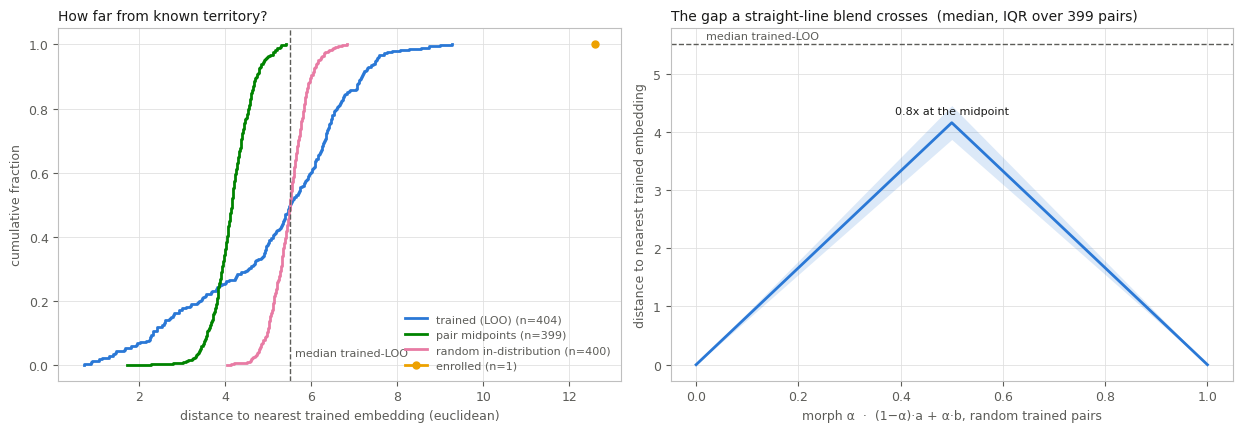

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))

ax = axes[0]
for i, (name, v) in enumerate(D.items()):
    x = np.sort(v)
    y = np.arange(1, len(x) + 1) / len(x)
    ax.step(x, y, where='post', lw=2, color=CAT[i % len(CAT)],
            marker='o' if len(x) <= 10 else None, ms=5,   # a 1-row series still draws
            label=f'{name} (n={len(v)})')
ax.axvline(D_MEDIAN_TRAINED, color=INK2, ls='--', lw=1)
ax.annotate('median trained-LOO', (D_MEDIAN_TRAINED, 0.03), xytext=(4, 0),
            textcoords='offset points', fontsize=8, color=INK2)
ax.set_xlabel(f'distance to nearest trained embedding ({METRIC})')
ax.set_ylabel('cumulative fraction')
ax.set_title('How far from known territory?', color=INK, fontsize=10, loc='left')
ax.legend(loc='lower right', frameon=False, fontsize=8, labelcolor=INK2)
ax.grid(True, **GRID)
ax.set_axisbelow(True)

ax = axes[1]
med = np.median(d_alpha, axis=1)
lo, hi = np.quantile(d_alpha, 0.25, axis=1), np.quantile(d_alpha, 0.75, axis=1)
ax.fill_between(ALPHA_GRID, lo, hi, color=CAT[0], alpha=0.16, lw=0)
ax.plot(ALPHA_GRID, med, lw=2, color=CAT[0])
ax.axhline(D_MEDIAN_TRAINED, color=INK2, ls='--', lw=1)
ax.annotate('median trained-LOO', (0.02, D_MEDIAN_TRAINED), xytext=(0, 4),
            textcoords='offset points', fontsize=8, color=INK2)
ax.annotate(f'{med.max() / D_MEDIAN_TRAINED:.1f}x at the midpoint',
            (ALPHA_GRID[med.argmax()], med.max()), xytext=(0, 6),
            textcoords='offset points', fontsize=8, color=INK, ha='center')
ax.set_xlabel('morph α  ·  (1−α)·a + α·b, random trained pairs')
ax.set_ylabel(f'distance to nearest trained embedding')
ax.set_title(f'The gap a straight-line blend crosses  (median, IQR over {len(ia)} pairs)',
             color=INK, fontsize=10, loc='left')
ax.grid(True, **GRID)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

### 2b · Does measured ESR track that distance?

The free version first: every point here is a **real** device with an ESR already measured on
disk, plotted against its leave-one-out distance to the rest of the trained table.

Read the two series separately — they are not the same measurement. Trained-device ESR comes
from `per_device_esr.csv` (test-split windows, the network *was* fit to those rows); enrolled
ESR comes from the enrollment run (frozen network, embedding-only fit). A relationship inside
the enrolled series is the interesting one: it is the only series where distance-from-known
was not chosen by the optimiser.

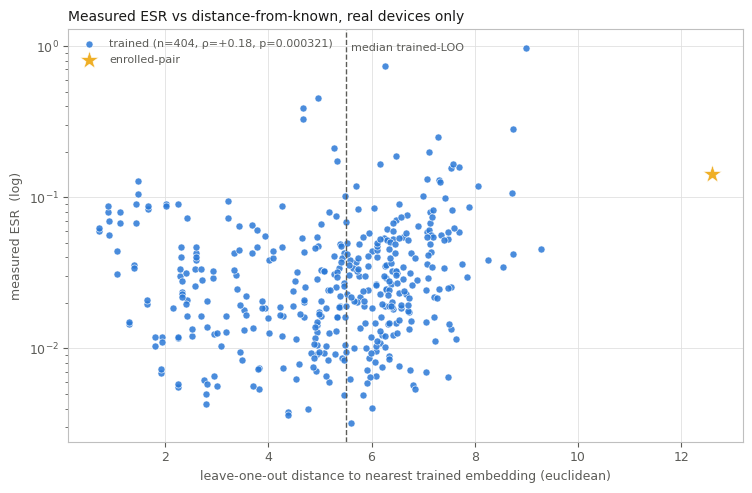

In [8]:
from scipy.stats import spearmanr

series = []
d_tr = D['trained (LOO)']
m = np.isfinite(TRAINED['esr'].to_numpy(dtype=float))
if m.any():
    series.append(('trained', d_tr[m], TRAINED['esr'].to_numpy(dtype=float)[m], CAT[0], 'o', 26))
if n_en:
    e_en = ENROLLED['esr'].to_numpy(dtype=float)
    for src, marker, size, slot in (('enrolled-holdout', 'D', 46, 1), ('enrolled-pair', '*', 190, 3)):
        mm = (ENROLLED['source'] == src).to_numpy() & np.isfinite(e_en)
        if mm.any():
            series.append((src, D['enrolled'][mm], e_en[mm], CAT[slot], marker, size))

fig, ax = plt.subplots(figsize=(7.6, 5.0))
for name, x, y, c, marker, size in series:
    lab = name
    if len(x) > 2:
        rho, p = spearmanr(x, y)
        lab = f'{name} (n={len(x)}, ρ={rho:+.2f}, p={p:.3g})'
    ax.scatter(x, y, s=size, marker=marker, c=c, linewidths=0.5, edgecolors='white',
               alpha=0.85, label=lab)
ax.set_yscale('log')
ax.axvline(D_MEDIAN_TRAINED, color=INK2, ls='--', lw=1)
ax.annotate('median trained-LOO', (D_MEDIAN_TRAINED, ax.get_ylim()[1]), xytext=(4, -10),
            textcoords='offset points', fontsize=8, color=INK2, va='top')
ax.set_xlabel(f'leave-one-out distance to nearest trained embedding ({METRIC})')
ax.set_ylabel('measured ESR  (log)')
ax.set_title('Measured ESR vs distance-from-known, real devices only',
             color=INK, fontsize=10, loc='left')
ax.legend(loc='best', frameon=False, fontsize=8, labelcolor=INK2)
ax.grid(True, **GRID)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

### 2c · The same question at *synthetic* points (renders audio)

Real devices can only ever be sampled where devices exist. To vary distance-from-known
continuously, walk the straight line between two trained amps and render at each step.
(*Morph*, not *sweep* — in this repo "sweep" is the log-sweep test signal, and the corpus
contains one; `WINDOW_SOURCES` is what filters that.)

At a blended point there is no ground truth, so quality is scored against the two real
endpoint renders and the **better of the two** is kept: `esr_min = min(ESR→a, ESR→b)` — "how
far is this output from the nearest amp we actually have". It rises for two different
reasons, and the third panel separates them:

- the blend is genuinely a *different* amp (legitimate, and what you want from a morph), or
- the blend is **broken** — FiLM gains partly cancelling, output level collapsing. That shows
  up as `level ratio = rms(y_α) / (rms(y_a)^(1−α) · rms(y_b)^α)` dipping below 1 mid-morph,
  independent of ESR. The reference is the *dB-linear* interpolation of the two endpoint
  levels, not an arithmetic crossfade: pairs here differ by up to ~20 dB, and an arithmetic
  reference tracks whichever amp is louder, which would read as collapse on its own.

Cost is `N_PAIRS × N_WINDOWS` forward passes, and it is CPU-contention bound — around a
minute on an idle box, several times that while a training run has the cores. Switch
`MORPH_DEVICE` to `'cuda'` only when the GPU is free — training runs live there.

In [9]:
from time import perf_counter

from openamp.dsp.audio import audio_info, seek_read

N_PAIRS = 24                                  # random trained pairs to walk
N_WINDOWS = 6                                 # audio windows per pair
WIN_SECONDS = 1.0
MORPH_ALPHAS = np.linspace(0.0, 1.0, 9)
MORPH_SPLIT = 'test'
WINDOW_SOURCES = None                          # e.g. ('egdb',) to keep sweep content out
MORPH_DEVICE = 'cpu'                          # 'cuda' when the GPU is free
MORPH_SEED = 7
SILENCE_DBFS = -50.0                          # matches evaluate.py's window gate

srng = np.random.default_rng(MORPH_SEED)
clip = int(WIN_SECONDS * cfg.sample_rate)
floor_rms = 10.0 ** (SILENCE_DBFS / 20.0)

# one fixed window set, reused for every pair (so pairs differ only in the amps).
# Files are drawn in proportion to duration -- uniform-over-files would over-weight
# the short sweep capture, whose ESR scale is nothing like the DI material's.
corpus = pd.read_parquet(cfg.corpus_manifest_path)
files = corpus[corpus['split'] == MORPH_SPLIT]
if WINDOW_SOURCES is not None:
    files = files[files['source'].isin(WINDOW_SOURCES)]
files = files.reset_index(drop=True)
weights = files['duration_s'].to_numpy(dtype=float)
weights = weights / weights.sum()

WINDOWS, tries = [], 0
while len(WINDOWS) < N_WINDOWS and tries < 20 * N_WINDOWS:
    tries += 1
    row = files.iloc[int(srng.choice(len(files), p=weights))]
    path = cfg.clean_split_dir(MORPH_SPLIT) / f'{row.file_id}.{cfg.output_format}'
    n = audio_info(path)[0]
    if n < R + clip + 1:
        continue
    c = int(srng.integers(R, n - clip))
    x = seek_read(path, c - R, R + clip)
    if np.sqrt(np.mean(x[R:] ** 2)) < floor_rms:      # skip silent lead-ins
        continue
    WINDOWS.append((row.file_id, c, x))

# devices whose renders cover every chosen window
renders = pd.read_parquet(cfg.renders_manifest_path)
ok = renders[(renders['status'] == 'render_ok') & (renders['split'] == MORPH_SPLIT)]
have = ok.groupby('device_id')['file_id'].agg(set)
need = {w[0] for w in WINDOWS}
ELIGIBLE = [d for d in TRAINED_IDS if need <= have.get(d, set())]
print(f'{len(WINDOWS)} windows x {WIN_SECONDS}s from '
      + ', '.join(f'{k} x{v}' for k, v in
                  pd.Series([w[0] for w in WINDOWS]).value_counts().items()))
print(f'{len(ELIGIBLE)}/{len(TRAINED_IDS)} trained devices renderable on all of them')


def esr(pred, target):
    return float(np.sum((pred - target) ** 2) / (np.sum(target ** 2) + 1e-12))


dev = torch.device(MORPH_DEVICE if (MORPH_DEVICE == 'cpu' or torch.cuda.is_available())
                   else 'cpu')
model.to(dev)
recs, t0 = [], perf_counter()
every = max(1, N_PAIRS // 8)
for pair_i in range(N_PAIRS):
    a, b = (int(v) for v in srng.choice(ELIGIBLE, size=2, replace=False))
    ea, eb = X_TRAINED[ID2ROW[a]], X_TRAINED[ID2ROW[b]]
    E_alpha = np.stack([(1 - t) * ea + t * eb for t in MORPH_ALPHAS]).astype(np.float32)
    d_nn = nn_distance(E_alpha)
    et = torch.from_numpy(E_alpha).to(dev)
    for fid, c, x in WINDOWS:
        try:
            ta = seek_read(cfg.device_render_dir(a) / f'{fid}.{cfg.output_format}', c, clip)
            tb = seek_read(cfg.device_render_dir(b) / f'{fid}.{cfg.output_format}', c, clip)
        except Exception as e:                     # rare libsndfile/NFS seek flake
            print(f'(skipped {fid} for {a}/{b}: {e!r})')
            continue
        rms_a, rms_b = np.sqrt(np.mean(ta ** 2)), np.sqrt(np.mean(tb ** 2))
        if min(rms_a, rms_b) < floor_rms:          # near-silent target: ESR denominator blows up
            continue
        xt = torch.from_numpy(x)[None].repeat(len(MORPH_ALPHAS), 1).to(dev)
        with torch.no_grad():
            y = model.forward_emb(xt, et)[:, 0, R:].float().cpu().numpy()
        for j, t in enumerate(MORPH_ALPHAS):
            recs.append({'pair': pair_i, 'a': a, 'b': b, 'file_id': fid, 'start': c,
                         'alpha': float(t), 'nn_dist': float(d_nn[j]),
                         'esr_a': esr(y[j], ta), 'esr_b': esr(y[j], tb),
                         'rms': float(np.sqrt(np.mean(y[j] ** 2))),
                         'rms_a': float(rms_a), 'rms_b': float(rms_b)})
    if (pair_i + 1) % every == 0:
        el = perf_counter() - t0
        print(f'  {pair_i + 1}/{N_PAIRS} pairs  {el:.0f}s  '
              f'(~{el / (pair_i + 1) * (N_PAIRS - pair_i - 1):.0f}s left)')
model.to('cpu')

MORPH = pd.DataFrame(recs)
MORPH['esr_min'] = MORPH[['esr_a', 'esr_b']].min(axis=1)
# expected level of a morph = dB-linear (geometric) interpolation of the two endpoints.
# An arithmetic crossfade would be dominated by whichever amp is louder, and these
# pairs differ by up to ~20 dB -- that bias would masquerade as level collapse.
MORPH['level_ratio'] = MORPH['rms'] / (MORPH['rms_a'] ** (1 - MORPH['alpha'])
                                       * MORPH['rms_b'] ** MORPH['alpha'])
print(f'{len(MORPH)} rendered points in {perf_counter() - t0:.0f}s '
      f'({MORPH["pair"].nunique()} pairs x {len(MORPH_ALPHAS)} α x '
      f'{MORPH.groupby(["pair", "alpha"]).size().max()} windows)')
MORPH.head()

6 windows x 1.0s from egdb_0215 x2, egdb_0190 x1, egdb_0075 x1, egdb_0207 x1, egdb_0115 x1
404/404 trained devices renderable on all of them


  3/24 pairs  45s  (~313s left)


  6/24 pairs  89s  (~268s left)


  9/24 pairs  134s  (~223s left)


  12/24 pairs  179s  (~179s left)


  15/24 pairs  223s  (~134s left)


  18/24 pairs  268s  (~89s left)


  21/24 pairs  313s  (~45s left)


  24/24 pairs  357s  (~0s left)
1296 rendered points in 357s (24 pairs x 9 α x 6 windows)


,pair,a,b,file_id,start,alpha,nn_dist,esr_a,esr_b,rms,rms_a,rms_b,esr_min,level_ratio
0,0,255,230,egdb_0190,968259,0.000,1.192093e-07,0.137121,1.140271,0.123378,0.112207,0.125336,0.137121,1.099560
1,0,255,230,egdb_0190,968259,0.125,1.116699e+00,0.186828,1.040577,0.084769,0.112207,0.125336,0.186828,0.745095
2,0,255,230,egdb_0190,968259,0.250,2.233398e+00,0.494534,1.172059,0.051221,0.112207,0.125336,0.494534,0.444036
3,0,255,230,egdb_0190,968259,0.375,3.350097e+00,0.979190,1.277002,0.027594,0.112207,0.125336,0.979190,0.235925
4,0,255,230,egdb_0190,968259,0.500,4.466797e+00,1.514267,1.076021,0.036251,0.112207,0.125336,1.076021,0.305686


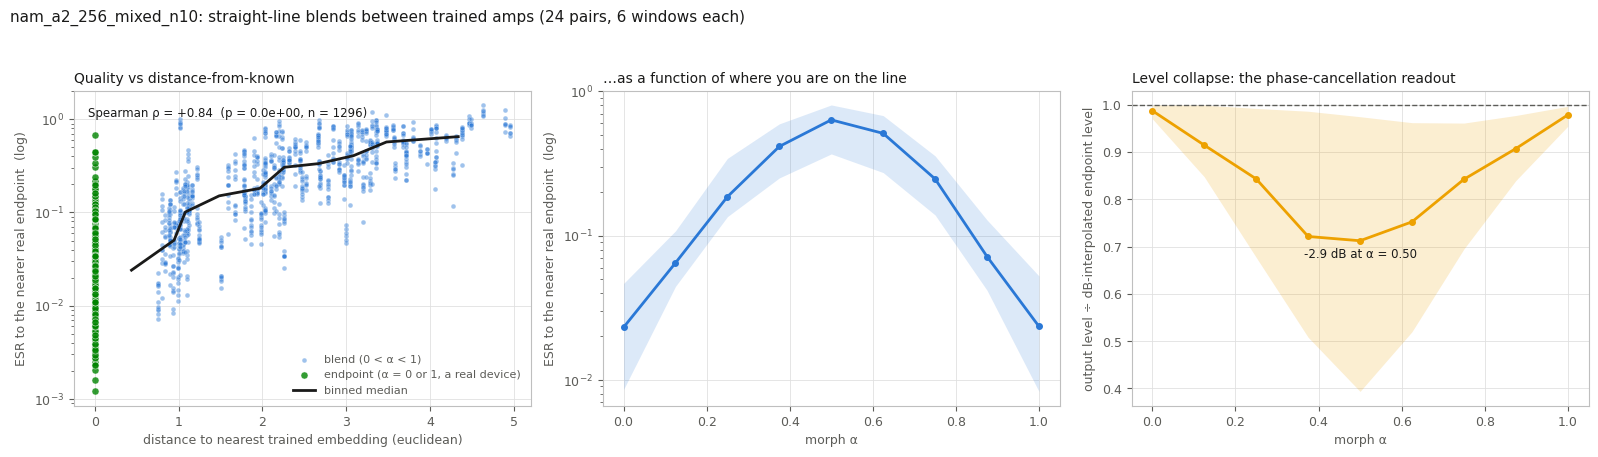

In [10]:
endpoints = MORPH['alpha'].isin([0.0, 1.0])
interior = ~endpoints

fig, axes = plt.subplots(1, 3, figsize=(16.0, 4.6))

ax = axes[0]
ax.scatter(MORPH.loc[interior, 'nn_dist'], MORPH.loc[interior, 'esr_min'], s=12,
           c=CAT[0], linewidths=0.3, edgecolors='white', alpha=0.45, label='blend (0 < α < 1)')
ax.scatter(MORPH.loc[endpoints, 'nn_dist'], MORPH.loc[endpoints, 'esr_min'], s=26,
           c=CAT[1], linewidths=0.4, edgecolors='white', alpha=0.8,
           label='endpoint (α = 0 or 1, a real device)')
q = np.quantile(MORPH['nn_dist'], np.linspace(0, 1, 13))
mid = 0.5 * (q[1:] + q[:-1])
binned = [MORPH.loc[(MORPH.nn_dist >= lo) & (MORPH.nn_dist < hi), 'esr_min'].median()
          for lo, hi in zip(q[:-1], q[1:])]
ax.plot(mid, binned, lw=2, color=INK, label='binned median')
rho, p = spearmanr(MORPH['nn_dist'], MORPH['esr_min'])
ax.annotate(f'Spearman ρ = {rho:+.2f}  (p = {p:.1e}, n = {len(MORPH)})',
            (0.03, 0.95), xycoords='axes fraction', fontsize=8.5, color=INK, va='top')
ax.set_yscale('log')
ax.set_xlabel(f'distance to nearest trained embedding ({METRIC})')
ax.set_ylabel('ESR to the nearer real endpoint  (log)')
ax.set_title('Quality vs distance-from-known', color=INK, fontsize=10, loc='left')
ax.legend(loc='lower right', frameon=False, fontsize=8, labelcolor=INK2)

ax = axes[1]
g = MORPH.groupby('alpha')['esr_min']
ax.fill_between(g.median().index, g.quantile(0.25), g.quantile(0.75),
                color=CAT[0], alpha=0.16, lw=0)
ax.plot(g.median().index, g.median().to_numpy(), lw=2, color=CAT[0], marker='o', ms=4)
ax.set_yscale('log')
ax.set_xlabel('morph α')
ax.set_ylabel('ESR to the nearer real endpoint  (log)')
ax.set_title('…as a function of where you are on the line', color=INK, fontsize=10, loc='left')

ax = axes[2]
g = MORPH.groupby('alpha')['level_ratio']
ax.fill_between(g.median().index, g.quantile(0.25), g.quantile(0.75),
                color=CAT[3], alpha=0.18, lw=0)
ax.plot(g.median().index, g.median().to_numpy(), lw=2, color=CAT[3], marker='o', ms=4)
ax.axhline(1.0, color=INK2, ls='--', lw=1)
worst = g.median().idxmin()
ax.annotate(f'{20 * np.log10(g.median().min()):+.1f} dB at α = {worst:.2f}',
            (worst, g.median().min()), xytext=(0, -12), textcoords='offset points',
            fontsize=8.5, color=INK, ha='center')
ax.set_xlabel('morph α')
ax.set_ylabel('output level ÷ dB-interpolated endpoint level')
ax.set_title('Level collapse: the phase-cancellation readout', color=INK, fontsize=10,
             loc='left')

for ax in axes:
    ax.grid(True, **GRID)
    ax.set_axisbelow(True)
fig.suptitle(f'{CK["name"]}: straight-line blends between trained amps '
             f'({MORPH["pair"].nunique()} pairs, {len(WINDOWS)} windows each)',
             color=INK, fontsize=11, x=0.005, ha='left')
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

## 3 · Is the space a shell?

If every trained vector has roughly the same length, the table lives on a thin spherical
shell. Then `(1−α)·a + α·b` — a chord through the ball — passes *inside* the shell: it is
shorter than either endpoint, so mid-morph the conditioning magnitude drops. For a
`film_wavenet` (FiLM is a `Linear` of the embedding) a shorter vector is literally weaker
modulation. `slerp` walks the arc instead, holding ‖e‖ constant, and is the right fix
**only in that case**.

The dip has a closed form when the two norms match: `‖(a+b)/2‖ / ‖a‖ = √((1+cos θ)/2)`. The
right-hand panel plots the measured dip against that curve, so you can see both how
shell-like the table is and how much length a straight line actually throws away.

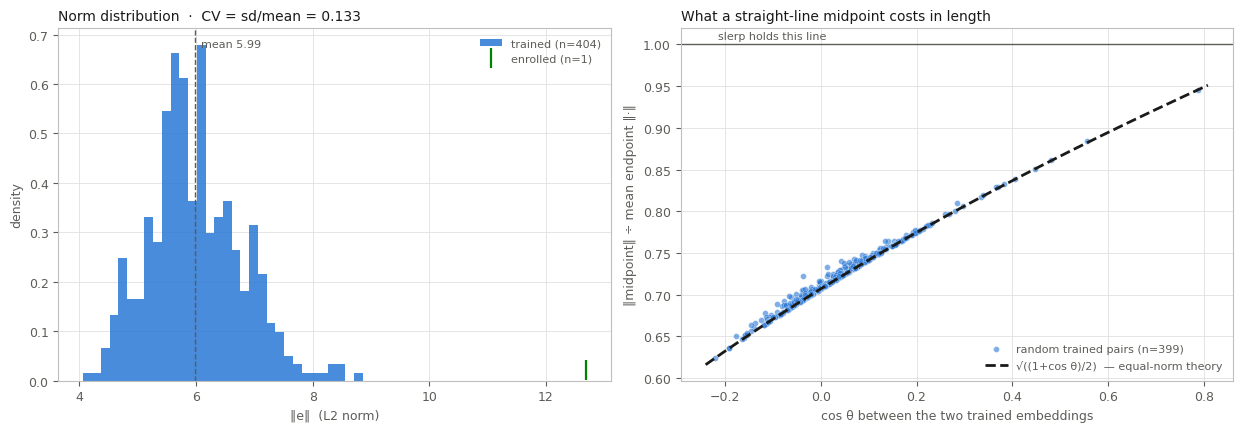

trained ‖e‖: mean 5.992  sd 0.796  CV 0.133  range 4.071–8.857
enrolled ‖e‖: mean 12.679  sd 0.000  range 12.679–12.679  (2.12x the trained mean)
cos θ between random trained pairs: median +0.025
midpoint length: median 0.719 of the endpoint mean (-2.86 dB of conditioning magnitude)
-> shell-like — slerp is the right interpolation


In [11]:
norm_tr = np.linalg.norm(X_TRAINED, axis=1)
norm_en = np.linalg.norm(X_ENROLLED, axis=1) if n_en else np.zeros(0)
cv = float(norm_tr.std() / norm_tr.mean())

na, nb = np.linalg.norm(A, axis=1), np.linalg.norm(B, axis=1)
cos_ab = np.sum(A * B, axis=1) / (na * nb)
dip = np.linalg.norm(0.5 * (A + B), axis=1) / (0.5 * (na + nb))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))

ax = axes[0]
ax.hist(norm_tr, bins=32, density=True, color=CAT[0], alpha=0.85,
        label=f'trained (n={n_tr})')
ax.axvline(norm_tr.mean(), color=INK2, ls='--', lw=1)
top = ax.get_ylim()[1]
ax.annotate(f'mean {norm_tr.mean():.2f}', (norm_tr.mean(), top), xytext=(4, -8),
            textcoords='offset points', fontsize=8, color=INK2, va='top')
if n_en:            # a rug, not a second histogram -- an enrolled set of 1 still reads
    ax.plot(norm_en, np.full(n_en, 0.03 * top), '|', ms=14, mew=1.6, color=CAT[1],
            label=f'enrolled (n={n_en})')
ax.set_xlabel('‖e‖  (L2 norm)')
ax.set_ylabel('density')
ax.set_title(f'Norm distribution  ·  CV = sd/mean = {cv:.3f}', color=INK, fontsize=10,
             loc='left')
ax.legend(loc='upper right', frameon=False, fontsize=8, labelcolor=INK2)

ax = axes[1]
ax.scatter(cos_ab, dip, s=18, c=CAT[0], linewidths=0.3, edgecolors='white', alpha=0.6,
           label=f'random trained pairs (n={len(dip)})')
cgrid = np.linspace(max(-0.99, cos_ab.min() - 0.02), min(1.0, cos_ab.max() + 0.02), 200)
ax.plot(cgrid, np.sqrt((1 + cgrid) / 2), lw=2, color=INK, ls='--',
        label='√((1+cos θ)/2)  — equal-norm theory')
ax.axhline(1.0, color=INK2, lw=1)
ax.annotate('slerp holds this line', (cos_ab.min(), 1.0), xytext=(2, 4),
            textcoords='offset points', fontsize=8, color=INK2)
ax.set_xlabel('cos θ between the two trained embeddings')
ax.set_ylabel('‖midpoint‖ ÷ mean endpoint ‖·‖')
ax.set_title('What a straight-line midpoint costs in length', color=INK, fontsize=10,
             loc='left')
ax.legend(loc='lower right', frameon=False, fontsize=8, labelcolor=INK2)

for ax in axes:
    ax.grid(True, **GRID)
    ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

verdict = ('shell-like — slerp is the right interpolation' if cv < 0.15 else
           'partly shell-like — slerp helps, but norm is a real degree of freedom too'
           if cv < 0.35 else
           'NOT a shell — lengths vary too much for slerp to be the fix')
print(f'trained ‖e‖: mean {norm_tr.mean():.3f}  sd {norm_tr.std():.3f}  '
      f'CV {cv:.3f}  range {norm_tr.min():.3f}–{norm_tr.max():.3f}')
if n_en:
    print(f'enrolled ‖e‖: mean {norm_en.mean():.3f}  sd {norm_en.std():.3f}  '
          f'range {norm_en.min():.3f}–{norm_en.max():.3f}  '
          f'({norm_en.mean() / norm_tr.mean():.2f}x the trained mean)')
print(f'cos θ between random trained pairs: median {np.median(cos_ab):+.3f}')
print(f'midpoint length: median {np.median(dip):.3f} of the endpoint mean '
      f'({20 * np.log10(np.median(dip)):+.2f} dB of conditioning magnitude)')
print(f'-> {verdict}')

## Reading it

- **§1** is qualitative. Groups that separate here are directions the network actually uses;
  a label that smears across the plot is not encoded (or not encoded linearly).
- **§2** is the quantitative version of the same picture, and `nn_distance` is reusable on any
  vector you build in `embedding_playground` — it answers "is this point in mapped territory?"
  before you listen.
- **§2b vs §2c**: §2b is free but only samples where devices exist; §2c walks the interior
  but has no ground truth, so it reports distance-to-the-nearer-endpoint plus an independent
  level check. A high ρ in §2c with a flat level ratio means blends are *different*, not
  broken; ρ plus a mid-morph level dip means the interpolation itself is at fault.
- **§3** decides whether slerp is even the right tool. Low CV ⇒ yes; high CV ⇒ the norm
  carries information and the fix is elsewhere.

Caveats worth keeping: enrolled and trained ESR come from different measurement protocols
(§2b), `tabledelta_wavenet` has no shared space at all, and every number is per-run — two runs'
tables are unrelated coordinate systems.